# Actividad: Flujo básico de modelado y MLflow Tracking

## AI4I 2020 Predictive Maintenance Dataset

### Objetivo

El objetivo de esta actividad es desarrollar un flujo básico y reproducible de Machine Learning, desde la exploración y preparación de los datos hasta el entrenamiento y evaluación de un modelo baseline y el registro del experimento mediante MLflow Tracking.

Para este análisis se utiliza el **AI4I 2020 Predictive Maintenance Dataset**, disponible en el UCI Machine Learning Repository. Este conjunto de datos representa un escenario industrial de mantenimiento predictivo y permite analizar variables relacionadas con las condiciones de operación de una máquina y la ocurrencia de fallas.

El problema será abordado inicialmente como una tarea de **clasificación**, utilizando la ocurrencia de una falla de máquina como variable objetivo.

## 1. Carga y descripción del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

In [2]:
# Carga del dataset original
df = pd.read_csv("data/ai4i2020.csv")

print("Dataset cargado correctamente.")
print(f"Número de registros: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")

df.head()

Dataset cargado correctamente.
Número de registros: 10,000
Número de variables: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [ ]:
print("Variables del dataset:")
for i, columna in enumerate(df.columns, start=1):
    print(f"{i:02d}. {columna}")

Variables del dataset:
01. UDI
02. Product ID
03. Type
04. Air temperature [K]
05. Process temperature [K]
06. Rotational speed [rpm]
07. Torque [Nm]
08. Tool wear [min]
09. Machine failure
10. TWF
11. HDF
12. PWF
13. OSF
14. RNF


### Descripción de las variables

El dataset contiene 10,000 registros y 14 variables. Las variables representan identificadores del producto, condiciones de operación de la máquina, desgaste de herramienta y diferentes indicadores asociados con fallas.

| Variable | Descripción |
|---|---|
| UDI | Identificador único de cada registro. |
| Product ID | Identificador del producto. |
| Type | Tipo o categoría de calidad del producto (L, M o H). |
| Air temperature [K] | Temperatura del aire expresada en Kelvin. |
| Process temperature [K] | Temperatura del proceso expresada en Kelvin. |
| Rotational speed [rpm] | Velocidad de rotación de la máquina en revoluciones por minuto. |
| Torque [Nm] | Torque del proceso expresado en Newton-metro. |
| Tool wear [min] | Tiempo acumulado de desgaste de la herramienta, expresado en minutos. |
| Machine failure | Variable objetivo que indica si ocurrió una falla de máquina (0 = no falla, 1 = falla). |
| TWF | Indicador de falla asociada al desgaste de herramienta (Tool Wear Failure). |
| HDF | Indicador de falla asociada a disipación de calor (Heat Dissipation Failure). |
| PWF | Indicador de falla relacionada con potencia (Power Failure). |
| OSF | Indicador de falla por sobreesfuerzo (Overstrain Failure). |
| RNF | Indicador de falla aleatoria (Random Failure). |

Los indicadores TWF, HDF, PWF, OSF y RNF representan modos específicos de falla. Debido a su relación directa con la ocurrencia de `Machine failure`, se evaluará posteriormente si deben excluirse de las variables predictoras para evitar fuga de información (*data leakage*).

## 2. Análisis exploratorio de datos (EDA)

El análisis exploratorio tiene como objetivo comprender la distribución de las variables, identificar posibles patrones y analizar su relación con la variable objetivo `Machine failure`.

Se revisarán estadísticas descriptivas, distribución de la variable objetivo, comportamiento de las variables numéricas y relaciones relevantes entre las características del proceso.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [6]:
type_distribution = df["Type"].value_counts()

print("Distribución por tipo de producto:")
print(type_distribution)

print("\nDistribución porcentual:")
print((df["Type"].value_counts(normalize=True) * 100).round(2))

Distribución por tipo de producto:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Distribución porcentual:
Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


In [7]:
failure_counts = df["Machine failure"].value_counts().sort_index()
failure_percent = df["Machine failure"].value_counts(
    normalize=True
).sort_index() * 100

failure_summary = pd.DataFrame({
    "Registros": failure_counts,
    "Porcentaje": failure_percent.round(2)
})

failure_summary.index = ["No Failure (0)", "Failure (1)"]

failure_summary

,Registros,Porcentaje
No Failure (0),9661,96.61
Failure (1),339,3.39


### Interpretación inicial del EDA

El dataset presenta variables de proceso con diferentes escalas, entre ellas temperatura, velocidad de rotación, torque y desgaste de herramienta. Esto deberá considerarse posteriormente durante la preparación de los datos para el modelo baseline.

La variable `Type` presenta una distribución de 60.00% para productos tipo L, 29.97% para tipo M y 10.03% para tipo H.

El principal hallazgo de esta etapa es el fuerte desbalance de la variable objetivo `Machine failure`. De los 10,000 registros, 9,661 (96.61%) corresponden a casos sin falla y únicamente 339 (3.39%) presentan una falla.

Este desbalance será considerado durante la evaluación del modelo, ya que utilizar únicamente accuracy podría producir una interpretación engañosa del desempeño. Por esta razón, además de accuracy, se considerarán métricas como precision, recall y F1-score, así como la matriz de confusión, con especial atención a la capacidad del modelo para identificar la clase minoritaria correspondiente a las fallas.

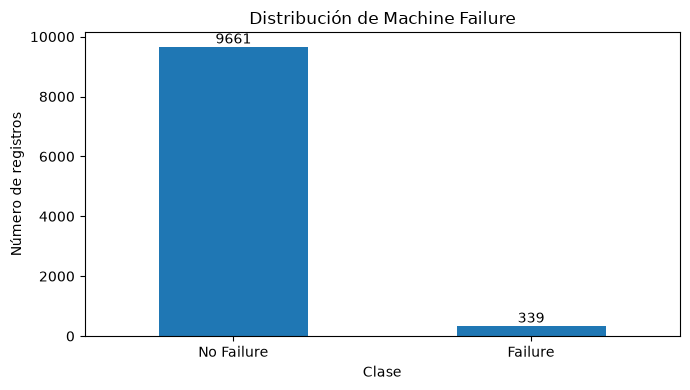

In [8]:
ax = failure_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

ax.set_title("Distribución de Machine Failure")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de registros")
ax.set_xticklabels(["No Failure", "Failure"], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

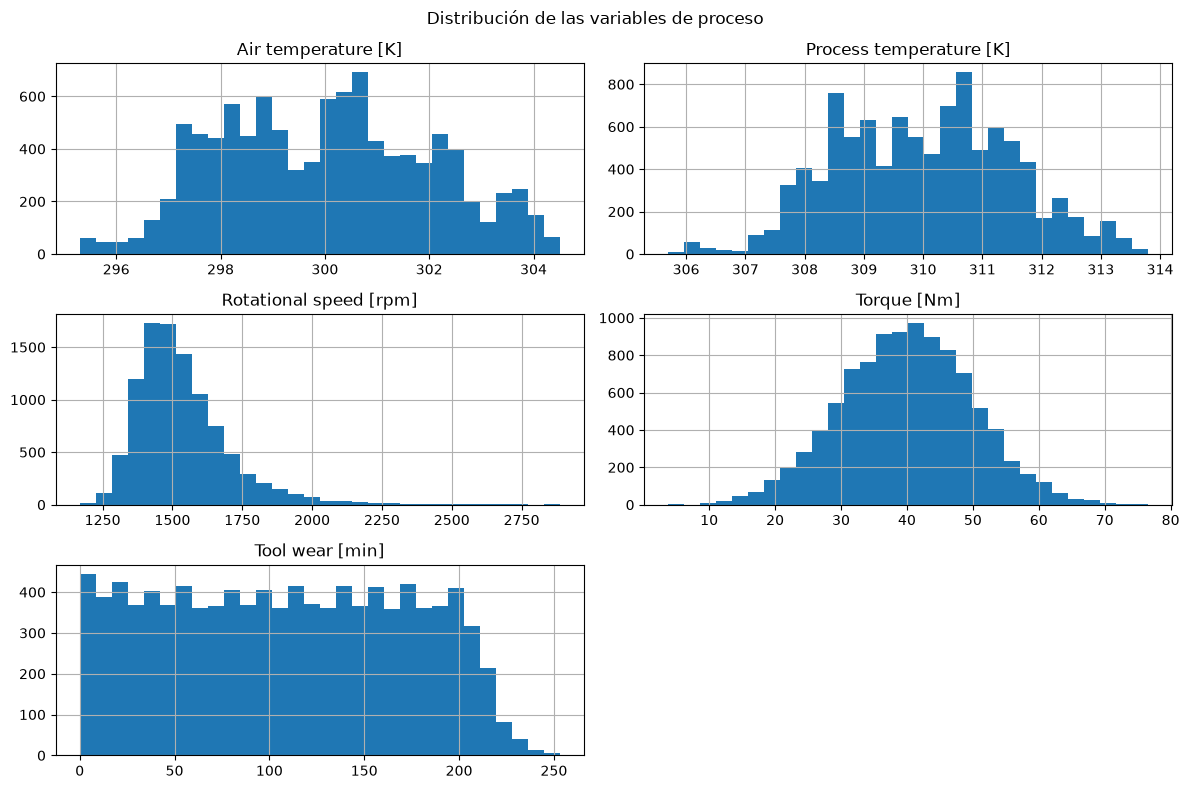

In [9]:
process_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[process_features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribución de las variables de proceso")
plt.tight_layout()
plt.show()

### Interpretación de las distribuciones

La visualización de la variable objetivo confirma el fuerte desbalance identificado previamente: los registros sin falla representan la gran mayoría de las observaciones, mientras que los eventos de falla constituyen una proporción considerablemente menor.

Respecto a las variables de proceso, se observan diferentes patrones de distribución. `Torque [Nm]` presenta una distribución aproximadamente simétrica alrededor de sus valores centrales, mientras que `Rotational speed [rpm]` muestra una distribución asimétrica con una cola hacia valores altos, lo que sugiere la presencia de observaciones extremas que deberán analizarse durante la etapa de limpieza.

`Tool wear [min]` presenta una distribución relativamente uniforme en gran parte de su rango, mientras que las variables de temperatura se concentran dentro de intervalos relativamente definidos.

Estas diferencias de escala y distribución deberán considerarse durante la preparación de los datos antes del entrenamiento del modelo.

In [10]:
failure_comparison = (
    df.groupby("Machine failure")[process_features]
      .mean()
      .T
)

failure_comparison.columns = ["No Failure", "Failure"]

failure_comparison
# Comparación de variables de proceso según Machine failure

,No Failure,Failure
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


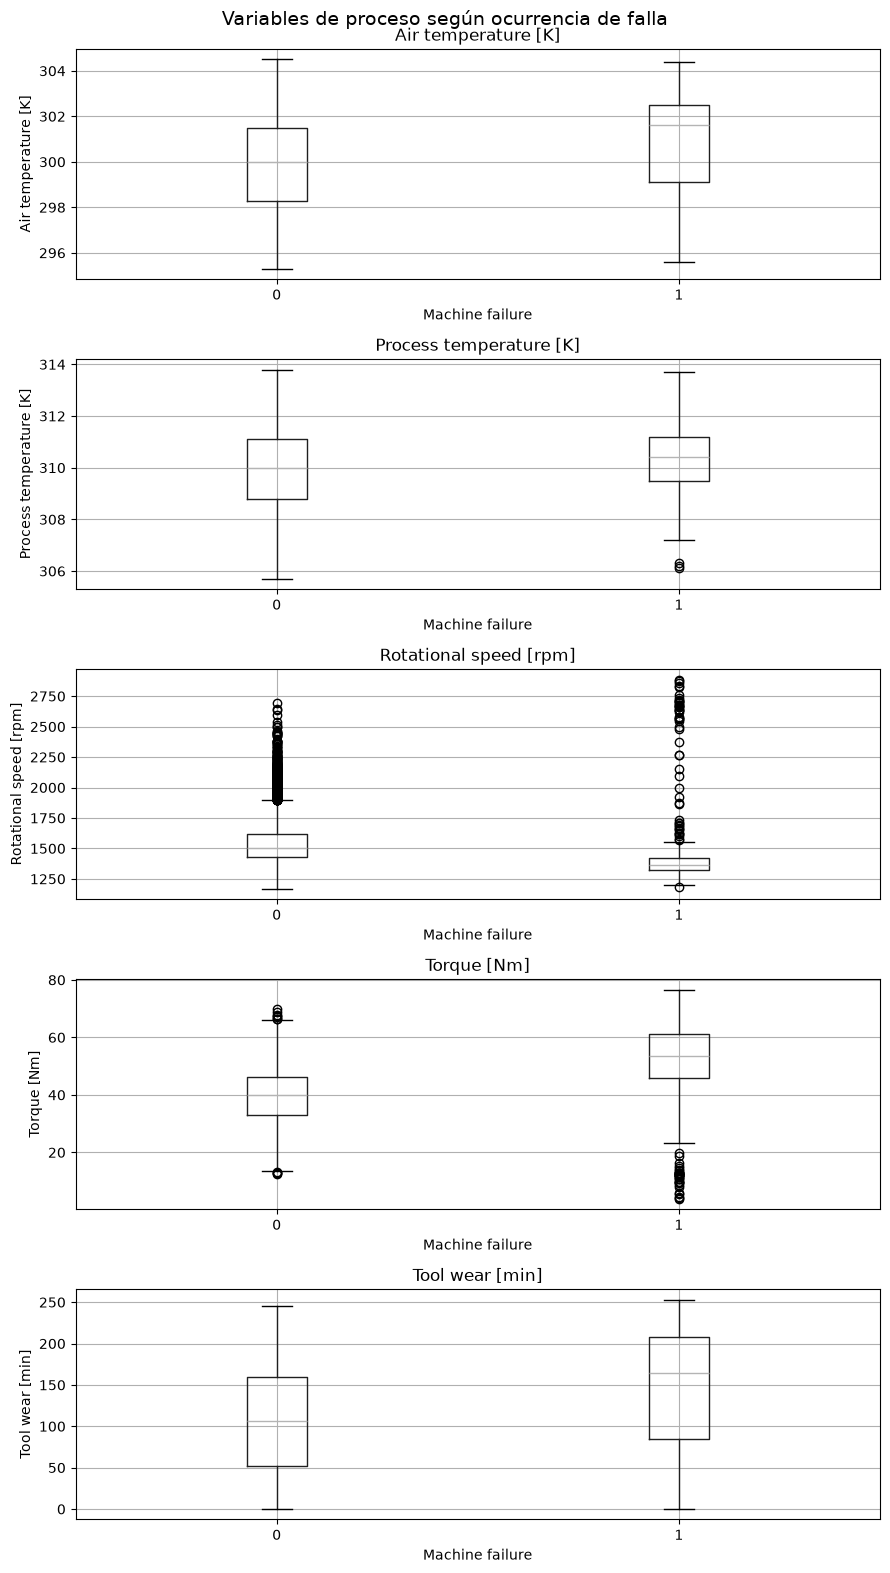

In [11]:
fig, axes = plt.subplots(
    nrows=len(process_features),
    ncols=1,
    figsize=(9, 16)
)

for ax, feature in zip(axes, process_features):
    df.boxplot(
        column=feature,
        by="Machine failure",
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Machine failure")
    ax.set_ylabel(feature)

plt.suptitle(
    "Variables de proceso según ocurrencia de falla",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Relación entre variables de proceso y ocurrencia de falla

La comparación entre las clases muestra diferencias en varias condiciones de operación. Los registros asociados con una falla presentan un torque promedio de aproximadamente 50.17 Nm, frente a 39.63 Nm en los registros sin falla. Asimismo, el desgaste promedio de herramienta aumenta de aproximadamente 106.69 min a 143.79 min cuando se presenta una falla.

La velocidad rotacional presenta el comportamiento contrario: los registros con falla muestran una velocidad promedio aproximada de 1,496 rpm, inferior a las 1,540 rpm observadas en los casos sin falla. También se observa una mayor temperatura del aire en los registros con falla, mientras que la diferencia en temperatura de proceso es menor.

Los diagramas de caja muestran además una cantidad importante de valores extremos en la velocidad rotacional y diferencias en la distribución del torque entre ambas clases. Sin embargo, existe solapamiento entre los grupos, por lo que ninguna de estas variables parece separar individualmente todos los casos de falla. Esto sugiere que la combinación de diferentes variables de proceso puede aportar mayor información para el modelo predictivo.

In [12]:
correlation_features = process_features + ["Machine failure"]

correlation_matrix = df[correlation_features].corr()

correlation_matrix.round(3)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,0.083
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,0.036
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.044
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.191
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,0.105
Machine failure,0.083,0.036,-0.044,0.191,0.105,1.000


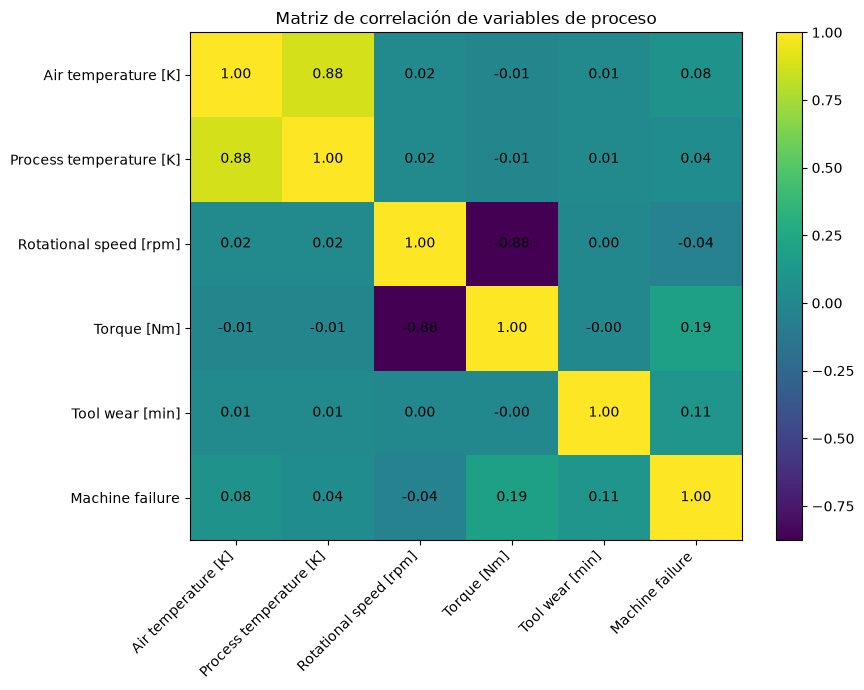

In [13]:
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    correlation_matrix,
    aspect="auto"
)

ax.set_xticks(range(len(correlation_features)))
ax.set_yticks(range(len(correlation_features)))

ax.set_xticklabels(
    correlation_features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_features)

for i in range(len(correlation_features)):
    for j in range(len(correlation_features)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Matriz de correlación de variables de proceso")

plt.colorbar(im)
plt.tight_layout()
plt.show()

### Interpretación de las correlaciones

La matriz de correlación muestra dos relaciones fuertes entre variables de proceso. `Air temperature [K]` y `Process temperature [K]` presentan una correlación positiva de aproximadamente 0.88, mientras que `Rotational speed [rpm]` y `Torque [Nm]` presentan una correlación negativa de aproximadamente -0.88.

Respecto a la variable objetivo, ninguna característica presenta individualmente una correlación lineal fuerte con `Machine failure`. La mayor asociación corresponde a `Torque [Nm]`, con una correlación aproximada de 0.19, seguida de `Tool wear [min]`, con 0.11.

Estos resultados sugieren que la ocurrencia de una falla no puede explicarse mediante una única variable de proceso y que la combinación de diferentes características puede aportar mayor capacidad predictiva. Asimismo, las correlaciones elevadas entre algunas variables predictoras deberán considerarse al interpretar posteriormente el modelo baseline.

In [14]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_mode_summary = pd.crosstab(
    df["Machine failure"],
    df[failure_modes].sum(axis=1),
    margins=True
)

failure_mode_summary

col_0,0,1,2,3,All
Machine failure,,,,,
0,9643,18,0,0,9661
1,9,306,23,1,339
All,9652,324,23,1,10000


In [15]:
df[["Machine failure"] + failure_modes].corr().round(3)

,Machine failure,TWF,HDF,PWF,OSF,RNF
Machine failure,1.000,0.363,0.576,0.523,0.531,0.005
TWF,0.363,1.000,-0.007,0.009,0.038,0.031
HDF,0.576,-0.007,1.000,0.018,0.046,-0.005
PWF,0.523,0.009,0.018,1.000,0.116,-0.004
OSF,0.531,0.038,0.046,0.116,1.000,-0.004
RNF,0.005,0.031,-0.005,-0.004,-0.004,1.000


### Análisis de los modos de falla y riesgo de data leakage

Se analizaron los indicadores `TWF`, `HDF`, `PWF`, `OSF` y `RNF`, los cuales representan modos específicos de falla incluidos en el dataset.

De los 339 registros clasificados como `Machine failure = 1`, 306 presentan un indicador de falla activo, 23 presentan dos y 1 presenta tres. También se identificaron 9 registros de falla sin ninguno de estos indicadores activo. Por otra parte, 18 registros clasificados como `Machine failure = 0` presentan un indicador activo.

Los indicadores HDF, OSF y PWF muestran además asociaciones considerablemente mayores con `Machine failure` que las variables operativas analizadas.

Debido a que estas variables describen directamente modos de falla y el objetivo del modelo es predecir `Machine failure` a partir de las condiciones de operación de la máquina, se excluirán del conjunto de variables predictoras. Esto permite reducir el riesgo de fuga de información (data leakage) y construir un baseline más representativo de un escenario predictivo.

## 3. Limpieza y preparación de los datos

En esta etapa se evaluará la calidad del dataset mediante la identificación de valores faltantes, registros duplicados, tipos de datos incorrectos y posibles valores atípicos. Cada decisión de limpieza será documentada antes de preparar las variables que serán utilizadas por el modelo baseline.

In [16]:
missing_values = df.isnull().sum()

pd.DataFrame({
    "Valores faltantes": missing_values,
    "Porcentaje (%)": (missing_values / len(df) * 100).round(2)
})

,Valores faltantes,Porcentaje (%)
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


In [17]:
duplicated_rows = df.duplicated().sum()

print(f"Registros duplicados: {duplicated_rows}")

Registros duplicados: 0


In [18]:
print(f"UDI duplicados: {df['UDI'].duplicated().sum()}")
print(f"Product ID duplicados: {df['Product ID'].duplicated().sum()}")

UDI duplicados: 0
Product ID duplicados: 0


### Valores faltantes y registros duplicados

No se identificaron valores faltantes en ninguna de las 14 variables del dataset. Asimismo, no se encontraron registros completamente duplicados.

Los identificadores `UDI` y `Product ID` tampoco presentan valores duplicados, por lo que cada observación conserva un identificador único.

Por lo tanto, no fue necesario eliminar registros ni aplicar técnicas de imputación por valores faltantes. El dataset conserva sus 10,000 observaciones originales después de estas verificaciones.

In [19]:
print("Valores únicos de Type:")
print(df["Type"].unique())

print("\nValores únicos de Machine failure:")
print(df["Machine failure"].unique())

for column in failure_modes:
    print(f"{column}: {df[column].unique()}")

Valores únicos de Type:
<ArrowStringArray>
['M', 'L', 'H']
Length: 3, dtype: str

Valores únicos de Machine failure:
[0 1]
TWF: [0 1]
HDF: [0 1]
PWF: [0 1]
OSF: [0 1]
RNF: [0 1]


In [20]:
outlier_summary = []

for feature in process_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_limit) |
        (df[feature] > upper_limit)
    ]

    outlier_summary.append({
        "Variable": feature,
        "Límite inferior": round(lower_limit, 2),
        "Límite superior": round(upper_limit, 2),
        "Outliers": len(outliers),
        "Porcentaje (%)": round(len(outliers) / len(df) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Variable,Límite inferior,Límite superior,Outliers,Porcentaje (%)
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


### Tipos de datos y tratamiento de valores atípicos

La revisión de las variables categóricas y binarias mostró valores consistentes con la definición del dataset. La variable `Type` contiene únicamente las categorías L, M y H, mientras que `Machine failure` y los indicadores de modos de falla presentan únicamente valores binarios 0 y 1. Por lo tanto, no se identificaron categorías inválidas que requirieran corrección.

Para identificar posibles valores atípicos en las variables de proceso se utilizó el método del rango intercuartílico (IQR). Se detectaron 418 observaciones atípicas en `Rotational speed [rpm]`, equivalentes al 4.18% de los registros, y 69 en `Torque [Nm]`, equivalentes al 0.69%. Las demás variables de proceso no presentaron valores fuera de los límites definidos mediante este criterio.

Los valores atípicos identificados no fueron eliminados. En el contexto de mantenimiento predictivo, condiciones extremas de velocidad o torque pueden representar comportamientos operativos reales y contener información relevante relacionada con la ocurrencia de fallas. Eliminarlos únicamente por su condición estadística de outlier podría provocar pérdida de información útil para el modelo.

In [21]:
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_columns].copy()
y = df["Machine failure"].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

X.head()

Dimensiones de X: (10000, 6)
Dimensiones de y: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


## 4. Entrenamiento del modelo baseline

Se seleccionó **Logistic Regression** como modelo baseline debido a que el problema corresponde a una tarea de clasificación binaria (`Machine failure`: 0 = no falla, 1 = falla). El objetivo de esta etapa no es optimizar el desempeño, sino establecer un punto de referencia reproducible para futuras iteraciones.

Los datos se dividirán en conjuntos de entrenamiento (80%) y prueba (20%). Debido al desbalance observado en la variable objetivo, se utilizará una división estratificada para conservar aproximadamente la misma proporción de fallas en ambos conjuntos.

Para evitar fuga de información durante el preprocesamiento, las transformaciones se integrarán dentro de un pipeline. Las variables numéricas serán estandarizadas mediante `StandardScaler`, mientras que la variable categórica `Type` será transformada mediante `OneHotEncoder`.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDistribución de Machine failure:")
print(f"Train: {y_train.mean() * 100:.2f}% fallas")
print(f"Test:  {y_test.mean() * 100:.2f}% fallas")

X_train: (8000, 6)
X_test: (2000, 6)
y_train: (8000,)
y_test: (2000,)

Distribución de Machine failure:
Train: 3.39% fallas
Test:  3.40% fallas


In [24]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [25]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [26]:
baseline_model.fit(X_train, y_train)

print("Modelo baseline entrenado correctamente.")

Modelo baseline entrenado correctamente.


## 5. Evaluación del modelo baseline

El modelo será evaluado utilizando el conjunto de prueba, el cual no fue utilizado durante el entrenamiento.

Debido al fuerte desbalance de la variable objetivo, la evaluación no se limitará a accuracy. Se analizarán también precision, recall y F1-score, además de la matriz de confusión. Estas métricas permitirán evaluar específicamente la capacidad del modelo para identificar los casos de falla, que representan la clase minoritaria.

In [27]:
y_pred = baseline_model.predict(X_test)

print("Predicciones generadas:", len(y_pred))

Predicciones generadas: 2000


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Valor": [accuracy, precision, recall, f1]
})

metrics

,Métrica,Valor
0,Accuracy,0.967500
1,Precision,0.636364
2,Recall,0.102941
3,F1-score,0.177215


In [29]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000



In [30]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[1928,    4],
       [  61,    7]])

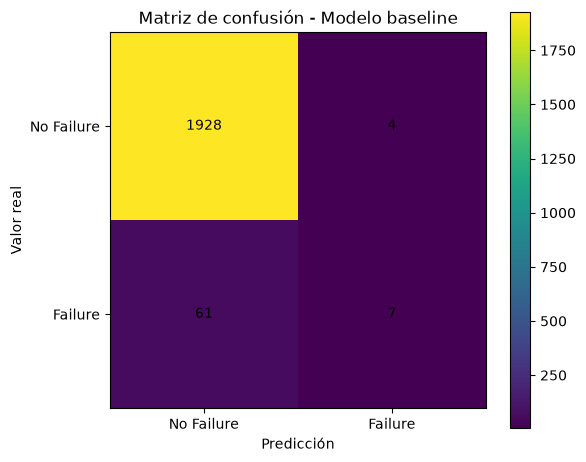

In [31]:
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm)

ax.set_title("Matriz de confusión - Modelo baseline")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["No Failure", "Failure"])
ax.set_yticklabels(["No Failure", "Failure"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.tight_layout()
plt.show()

### Interpretación del desempeño del modelo baseline

El modelo baseline obtuvo un accuracy de 95.75%. Sin embargo, esta métrica debe interpretarse con precaución debido al fuerte desbalance de la variable objetivo identificado durante el análisis exploratorio.

En el conjunto de prueba existen 68 casos reales de falla. El modelo identificó correctamente únicamente 7 de ellos y clasificó 61 fallas como casos sin falla. Esto produce un recall de 10.29%, lo que significa que el modelo detecta aproximadamente una de cada diez fallas reales.

La precision para la clase de falla fue de 63.64%, indicando que, cuando el modelo predice una falla, aproximadamente el 64% de esas predicciones son correctas. No obstante, el bajo recall y el F1-score de 17.72% muestran que el modelo presenta una capacidad limitada para identificar la clase minoritaria.

La matriz de confusión confirma este comportamiento: se obtuvieron 1,928 verdaderos negativos, 4 falsos positivos, 61 falsos negativos y únicamente 7 verdaderos positivos.

Por lo tanto, aunque el accuracy global parece elevado, el modelo baseline no presenta todavía un desempeño adecuado para la detección de fallas. Este resultado constituye un punto de referencia para futuras iteraciones, en las cuales podrían evaluarse estrategias para tratar el desbalance de clases, ajustar el umbral de clasificación, realizar ingeniería de características y comparar otros algoritmos.

## 6. Registro del experimento con MLflow Tracking

Para mantener trazabilidad y reproducibilidad del experimento, el modelo baseline será registrado mediante MLflow Tracking.

Se registrarán los principales parámetros utilizados durante el entrenamiento y las métricas obtenidas en el conjunto de prueba. Adicionalmente, se almacenará la matriz de confusión como artefacto del experimento.

In [32]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("AI4I_Baseline")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento configurado correctamente.")

2026/10/01 15:56:56 INFO mlflow.tracking.fluent: Experiment with name 'AI4I_Baseline' does not exist. Creating a new experiment.


Tracking URI: http://127.0.0.1:5000
Experimento configurado correctamente.


In [35]:
from pathlib import Path

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

confusion_matrix_path = artifact_dir / "confusion_matrix_baseline.png"

In [37]:
from pathlib import Path
import os

print("Directorio actual del notebook:")
print(Path.cwd())

print("\n¿Existe artifacts desde aquí?")
print(Path("artifacts").exists())

print("\nContenido del directorio actual:")
print(os.listdir())

Directorio actual del notebook:
c:\Users\aip\Documents\GitHub\TC5062-A01797871\mlflow_actividad\actividad_baseline

¿Existe artifacts desde aquí?
True

Contenido del directorio actual:
['actividad_baseline.ipynb', 'artifacts', 'data']


In [40]:
from pathlib import Path

artifact_dir = Path(r"C:\Users\aip\mlflow_tracking\artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

confusion_matrix_path = artifact_dir / "confusion_matrix_baseline.png"

print("Carpeta:", artifact_dir)
print("Existe:", artifact_dir.exists())
print("Es carpeta:", artifact_dir.is_dir())

Carpeta: C:\Users\aip\mlflow_tracking\artifacts
Existe: True
Es carpeta: True


In [41]:
test_file = artifact_dir / "prueba.txt"

with open(test_file, "w", encoding="utf-8") as f:
    f.write("Prueba de escritura correcta.")

print("Archivo creado:", test_file)

Archivo creado: C:\Users\aip\mlflow_tracking\artifacts\prueba.txt


In [42]:
plt.savefig(
    confusion_matrix_path,
    dpi=150,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [43]:
confusion_matrix_path

WindowsPath('C:/Users/aip/mlflow_tracking/artifacts/confusion_matrix_baseline.png')

In [44]:
with mlflow.start_run(run_name="LogisticRegression_Baseline") as run:

    # Parámetros del experimento
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("stratified_split", True)
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("numeric_scaler", "StandardScaler")
    mlflow.log_param("categorical_encoder", "OneHotEncoder")

    # Métricas de evaluación
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    # Artefacto de evaluación
    mlflow.log_artifact(
        str(confusion_matrix_path),
        artifact_path="evaluation"
    )

    run_id = run.info.run_id

print("Experimento registrado correctamente.")
print("Run ID:", run_id)

🏃 View run LogisticRegression_Baseline at: http://127.0.0.1:5000/#/experiments/1/runs/6e3e0c0871924f548d9b00450463872d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Experimento registrado correctamente.
Run ID: 6e3e0c0871924f548d9b00450463872d


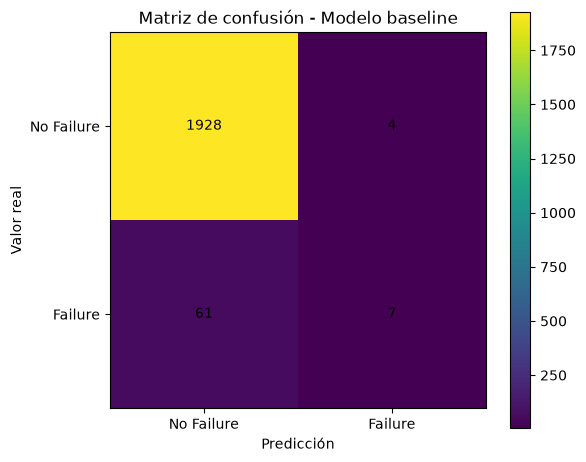

Matriz guardada correctamente en:
C:\Users\aip\mlflow_tracking\artifacts\confusion_matrix_baseline.png
Tamaño del archivo: 30732 bytes


In [45]:
confusion_matrix_path = Path(
    r"C:\Users\aip\mlflow_tracking\artifacts\confusion_matrix_baseline.png"
)

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm)

ax.set_title("Matriz de confusión - Modelo baseline")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["No Failure", "Failure"])
ax.set_yticklabels(["No Failure", "Failure"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)
fig.tight_layout()

# IMPORTANTE: guardar directamente desde el objeto fig
fig.savefig(
    confusion_matrix_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Matriz guardada correctamente en:")
print(confusion_matrix_path)
print("Tamaño del archivo:", confusion_matrix_path.stat().st_size, "bytes")

In [46]:
with mlflow.start_run(run_id=run_id):

    mlflow.log_artifact(
        str(confusion_matrix_path),
        artifact_path="evaluation"
    )

print("Artefacto actualizado correctamente en MLflow.")

🏃 View run LogisticRegression_Baseline at: http://127.0.0.1:5000/#/experiments/1/runs/6e3e0c0871924f548d9b00450463872d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Artefacto actualizado correctamente en MLflow.


## 7. Reflexión final

El desarrollo de este modelo baseline permitió comprobar que el desempeño de un modelo de Machine Learning no debe evaluarse únicamente mediante una métrica general. Aunque la regresión logística obtuvo un accuracy de 95.75%, el análisis detallado mostró un recall de apenas 10.29% para la detección de fallas. Esto significa que el modelo identificó únicamente 7 de las 68 fallas reales presentes en el conjunto de prueba. En un escenario industrial, esta diferencia es especialmente relevante, ya que un modelo con alta exactitud global podría aparentar un buen desempeño mientras continúa omitiendo la mayoría de los eventos que se desean anticipar.

En futuras iteraciones mejoraría este flujo mediante prácticas de MLOps orientadas a la reproducibilidad, trazabilidad y comparación sistemática de experimentos. MLflow permitiría registrar diferentes modelos, hiperparámetros, métricas y artefactos para comparar objetivamente cada iteración. También sería importante incorporar versionado de datos y código, automatización del pipeline, validaciones de calidad de datos y monitoreo del desempeño del modelo una vez desplegado. A nivel de modelado, evaluaría estrategias para tratar el desbalance de clases, diferentes umbrales de clasificación, ingeniería de características y algoritmos alternativos, utilizando métricas como recall, precision y F1-score para comparar los resultados.

Estos aprendizajes tienen una aplicación directa en mi área profesional, particularmente en manufactura, calidad y análisis de procesos. En estos entornos, los datos provenientes de parámetros de proceso, inspecciones y resultados de calidad pueden utilizarse para desarrollar modelos orientados a detectar patrones asociados con fallas. Sin embargo, para que estos modelos aporten valor operativo no basta con entrenarlos: es necesario conocer qué datos y parámetros generaron cada resultado, poder reproducir los experimentos y monitorear si su comportamiento cambia con nuevos datos. La incorporación de prácticas de MLOps permite transformar un análisis experimental en un proceso controlado, trazable y susceptible de mejora continua.

### Nota sobre el registro de artefactos

Durante el registro del artefacto se presentaron restricciones de escritura asociadas al entorno local de ejecución. Se realizaron diferentes verificaciones de ruta y permisos hasta establecer una ubicación válida para almacenar la matriz de confusión y registrarla posteriormente en MLflow.

Se conservan estas pruebas como evidencia del proceso de diagnóstico y de la solución implementada.

## Uso de herramientas de Inteligencia Artificial Generativa

Durante el desarrollo de esta actividad se utilizó **ChatGPT (OpenAI)** como herramienta de apoyo complementario.

Su uso se enfocó principalmente en:

- Revisión y mejora de redacción, gramática y claridad de las explicaciones incluidas en el notebook.
- Apoyo para identificar, interpretar y corregir errores presentados durante la ejecución del código.
- Asistencia en la depuración de problemas relacionados con rutas, permisos de escritura y almacenamiento de artefactos, orientación para la configuración y uso de MLflow Tracking durante el registro del experimento.
- Revisión de la estructura del notebook y verificación del cumplimiento de los requerimientos de la actividad.

Las decisiones relacionadas con la selección del dataset, ejecución del código, análisis de resultados, validación de las soluciones implementadas y conclusiones de la actividad fueron revisadas por mi durante el desarrollo del ejercicio.

### Referencia

OpenAI. (2026). *ChatGPT* (GPT-5.6 Sol) [Modelo de lenguaje de inteligencia artificial]. OpenAI.